In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from tqdm import tqdm

In [2]:
df_deals = pd.read_csv('../data/deals_all_opt.csv')
df_deals['entry_date'] = pd.to_datetime(df_deals['entry_date'])
df_deals['exit_date'] = pd.to_datetime(df_deals['exit_date'])

In [3]:
candles_dict = {}
instruments = df_deals['instrument'].unique()
data_dir = '../data/candles'
for inst in tqdm(instruments):
    file_path = f"{data_dir}/{inst}_15m.csv"
    
    if os.path.exists(file_path):
        df_c = pd.read_csv(file_path)
        df_c['timestamp'] = pd.to_datetime(df_c['timestamp'])
        df_c.set_index('timestamp', inplace=True)
        df_c = df_c[~df_c.index.duplicated(keep='last')]
        df_c.sort_index(inplace=True)
        candles_dict[inst] = df_c

100%|██████████████████████████████████████████| 21/21 [00:02<00:00,  7.30it/s]


In [4]:
candles_dict['SOL-USDT-SWAP']

,open,high,low,close,vol
timestamp,,,,,
2021-03-30 03:00:00,19.854,19.963,19.747,19.963,8341.00
2021-03-30 03:15:00,19.962,20.060,19.848,19.877,22700.00
2021-03-30 03:30:00,19.890,19.898,19.746,19.842,8649.00
2021-03-30 03:45:00,19.843,20.019,19.779,20.017,8786.00
2021-03-30 04:00:00,20.016,20.034,19.821,19.830,9938.00
...,...,...,...,...,...
2025-12-05 12:45:00,136.700,136.910,136.510,136.620,90197.63
2025-12-05 13:00:00,136.610,137.020,136.050,136.550,95163.60
2025-12-05 13:15:00,136.550,136.820,136.330,136.820,51279.00


In [5]:
df_deals['S'] = np.where(df_deals['direction'] == 'Long', 1, -1)
df_deals['w'] = df_deals['volume'] / df_deals['start_equity']
df_deals['c'] = df_deals['commission'] / df_deals['start_equity']

df_deals['A'] = df_deals['S'] * df_deals['w'] * 100
df_deals['B'] = df_deals['S'] * df_deals['entry_price'] * df_deals['w'] * 100
df_deals['C'] = df_deals['c'] * 100

df_deals['entry_time'] = df_deals['entry_date'].dt.floor('15min')
df_deals['exit_time'] = df_deals['exit_date'].dt.floor('15min')

In [6]:
start_t = df_deals['entry_time'].min()
end_t = df_deals['exit_time'].max()

master_timeline = pd.date_range(start=start_t, end=end_t, freq='15min')

total_floating_pnl = pd.Series(0.0, index=master_timeline)

### 15-минутные

In [7]:
for inst in instruments:
    if inst not in candles_dict:
        continue
        
    inst_deals = df_deals[df_deals['instrument'] == inst]
    
    entries = inst_deals[['entry_time', 'A', 'B', 'C']].copy()
    entries.columns = ['time', 'A', 'B', 'C']
    
    exits = inst_deals[['exit_time', 'A', 'B', 'C']].copy()
    exits.columns = ['time', 'A', 'B', 'C']
    exits[['A', 'B', 'C']] = -exits[['A', 'B', 'C']]

    events = pd.concat([entries, exits]).groupby('time').sum()
    events = events[events.index.notnull()]
    events = events.reindex(master_timeline).fillna(0).cumsum()
    close_prices = candles_dict[inst]['close'].reindex(master_timeline).ffill()
    inst_floating = close_prices * events['A'] - events['B'] - events['C']
    total_floating_pnl = total_floating_pnl.add(inst_floating.fillna(0), fill_value=0)

### Закрытые сделки

In [8]:
fixed_events = df_deals.groupby('exit_time')['profit_eq_pc'].sum()
total_fixed_pnl = fixed_events.reindex(master_timeline).fillna(0).cumsum()

In [9]:
portfolio_equity_curve = total_fixed_pnl + total_floating_pnl

In [10]:
peak_curve = portfolio_equity_curve.cummax()
drawdown_curve = portfolio_equity_curve - peak_curve
max_drawdown = abs(drawdown_curve.min())
print(max_drawdown)

-54.458571758264924


In [11]:
returns_15m = portfolio_equity_curve.diff().fillna(0)
N_PERIODS_YEAR = 365 * 24 * 4 
mean_ret = returns_15m.mean()
std_ret = returns_15m.std()

In [12]:
sharpe_ratio = (mean_ret / std_ret) * np.sqrt(N_PERIODS_YEAR)

neg_returns = returns_15m[returns_15m < 0]
downside_std = np.sqrt((neg_returns**2).mean())
sortino_ratio = (mean_ret / downside_std) * np.sqrt(N_PERIODS_YEAR)

total_net_profit = portfolio_equity_curve.iloc[-1]
recovery_factor = total_net_profit / max_drawdown


print(recovery_factor)
print(sharpe_ratio)
print(sortino_ratio)

-8.45595938306431
2.3247338935691686
2.3352895316632596


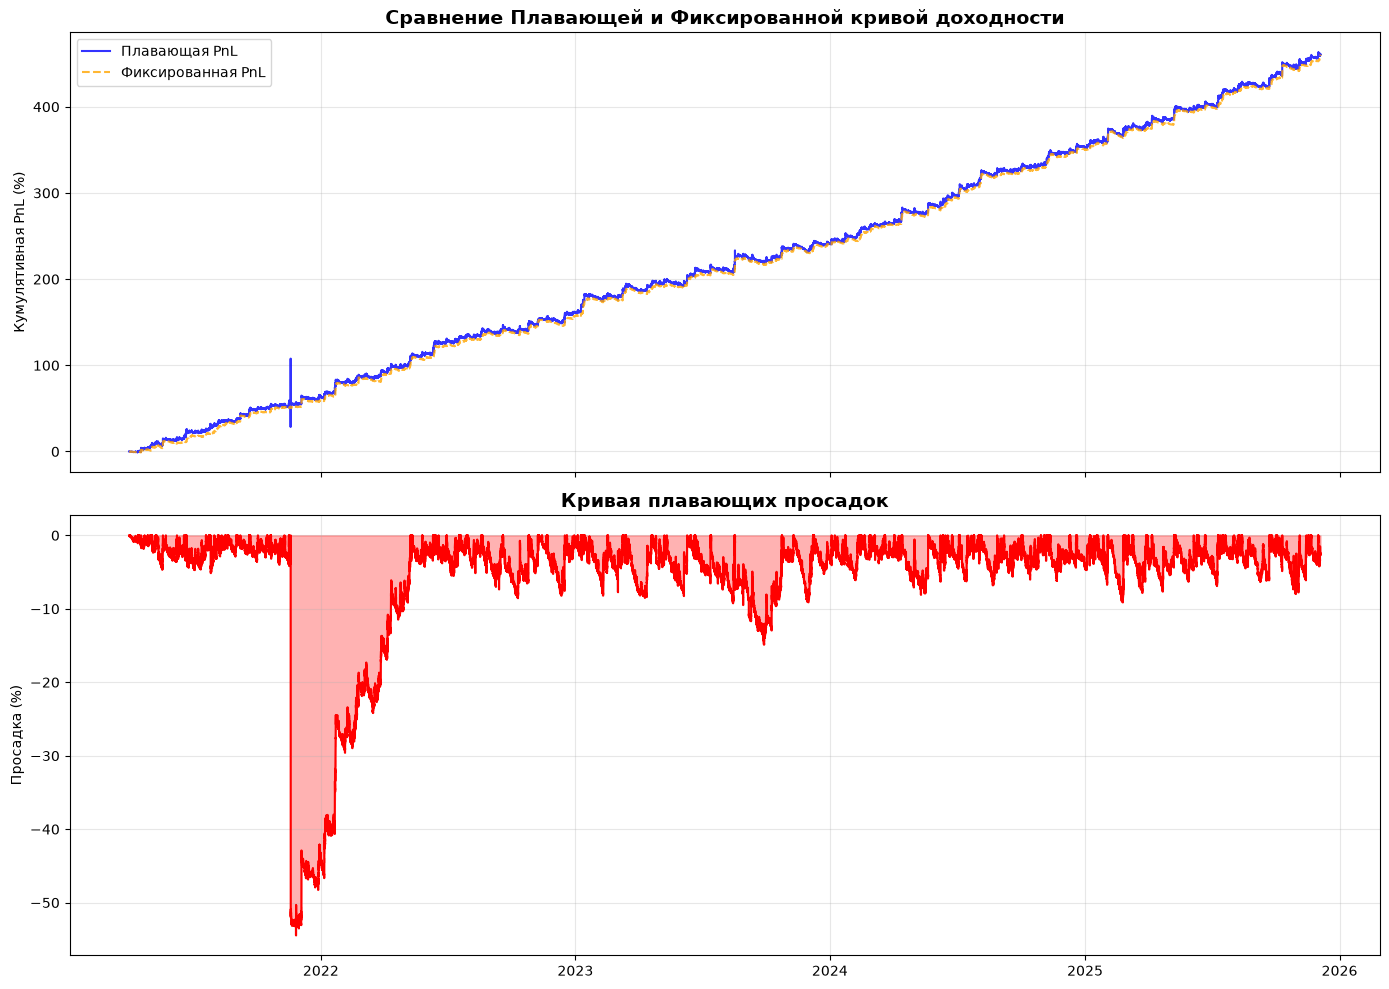

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

ax1.plot(portfolio_equity_curve.index, portfolio_equity_curve, label='Плавающая PnL', color='blue', alpha=0.8)
ax1.plot(total_fixed_pnl.index, total_fixed_pnl, label='Фиксированная PnL', color='orange', linestyle='--', alpha=0.8)
ax1.set_title('Сравнение Плавающей и Фиксированной кривой доходности', fontsize=14, fontweight='bold')
ax1.set_ylabel('Кумулятивная PnL (%)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(drawdown_curve.index, drawdown_curve, color='red', linewidth=1.5)
ax2.fill_between(drawdown_curve.index, drawdown_curve, 0, color='red', alpha=0.3)
ax2.set_title('Кривая плавающих просадок', fontsize=14, fontweight='bold')
ax2.set_ylabel('Просадка (%)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
sma_window = 7 * 24 * 4
equity_sma = portfolio_equity_curve.ewm(span=sma_window, adjust=False).mean()

trade_signal = (portfolio_equity_curve > equity_sma).astype(int)
trade_signal = trade_signal.shift(1).fillna(1)

filtered_returns = returns_15m * trade_signal
filtered_equity_curve = filtered_returns.cumsum()

peak_filtered = filtered_equity_curve.cummax()
drawdown_filtered = filtered_equity_curve - peak_filtered
max_dd_filtered = drawdown_filtered.min()

mean_ret_f = filtered_returns.mean()
std_ret_f = filtered_returns.std()
N_PERIODS_YEAR = 365 * 24 * 4

sharpe_f = (mean_ret_f / std_ret_f) * np.sqrt(N_PERIODS_YEAR) if std_ret_f > 0 else 0

neg_ret_f = filtered_returns[filtered_returns < 0]
downside_std_f = np.sqrt((neg_ret_f**2).mean())
sortino_f = (mean_ret_f / downside_std_f) * np.sqrt(N_PERIODS_YEAR) if downside_std_f > 0 else 0

total_net_profit_f = filtered_equity_curve.iloc[-1]
recovery_factor_f = total_net_profit_f / abs(max_dd_filtered) if max_dd_filtered < 0 else 0

print(f"Максимальная просадка: {max_dd_filtered:.2f}%")
print(f"Фактор восстановления: {recovery_factor_f:.2f}")
print(f"Коэффициент Шарпа: {sharpe_f:.2f}")
print(f"Коэффициент Сортино: {sortino_f:.2f}")

Максимальная просадка: -56.03%
Фактор восстановления: 4.43
Коэффициент Шарпа: 1.44
Коэффициент Сортино: 1.03


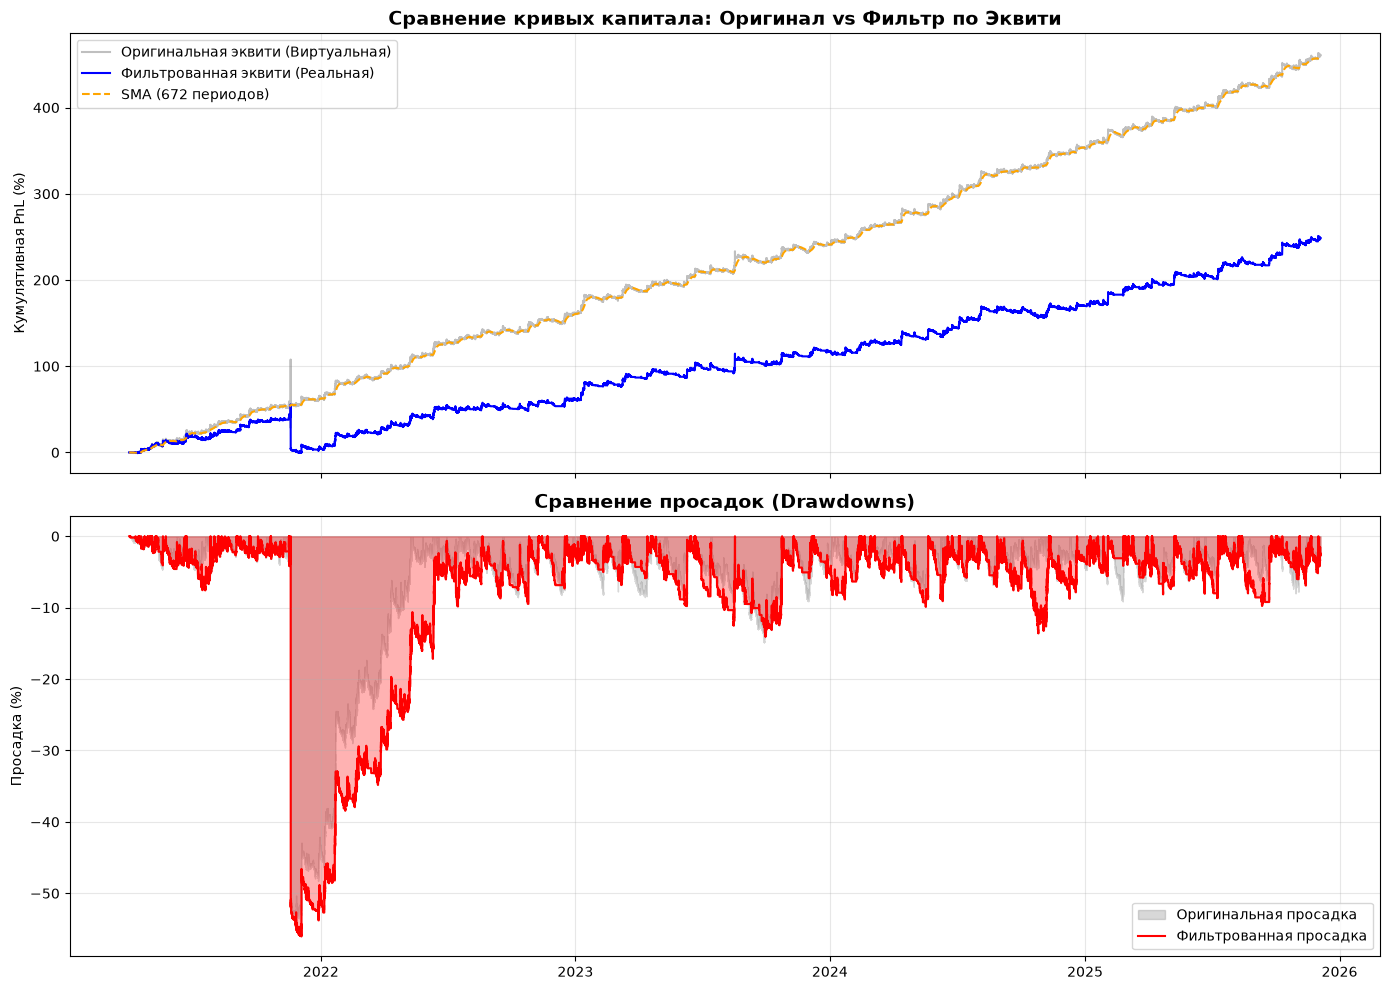

In [26]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

ax1.plot(portfolio_equity_curve.index, portfolio_equity_curve, label='Оригинальная эквити (Виртуальная)', color='gray', alpha=0.5)
ax1.plot(filtered_equity_curve.index, filtered_equity_curve, label='Фильтрованная эквити (Реальная)', color='blue', linewidth=1.5)
ax1.plot(equity_sma.index, equity_sma, label=f'SMA ({sma_window} периодов)', color='orange', linestyle='--')
ax1.set_title('Сравнение кривых капитала: Оригинал vs Фильтр по Эквити', fontsize=14, fontweight='bold')
ax1.set_ylabel('Кумулятивная PnL (%)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.fill_between(drawdown_curve.index, drawdown_curve, 0, color='gray', alpha=0.3, label='Оригинальная просадка')
ax2.plot(drawdown_filtered.index, drawdown_filtered, color='red', linewidth=1.5, label='Фильтрованная просадка')
ax2.fill_between(drawdown_filtered.index, drawdown_filtered, 0, color='red', alpha=0.3)
ax2.set_title('Сравнение просадок (Drawdowns)', fontsize=14, fontweight='bold')
ax2.set_ylabel('Просадка (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# 1. Настройки канала (Bollinger Bands для Эквити)
window = 7 * 24 * 4  # Окно расчета: 7 дней
std_multiplier = 2.0 # Ширина канала (2 стандартных отклонения)

# 2. Расчет линий канала
equity_mean = portfolio_equity_curve.rolling(window=window).mean()
equity_std = portfolio_equity_curve.rolling(window=window).std()

# Нижняя граница (отбойник)
lower_band = equity_mean - (std_multiplier * equity_std)

# 3. Формирование асимметричного сигнала (Векторный конечный автомат)
raw_signal = pd.Series(index=portfolio_equity_curve.index, dtype=float)

# Красный свет: эквити пробила нижнюю границу (отключаем)
raw_signal[portfolio_equity_curve < lower_band] = 0.0

# Зеленый свет: эквити вернулась выше средней линии (включаем)
raw_signal[portfolio_equity_curve > equity_mean] = 1.0

# Заполняем промежутки предыдущим состоянием (ffill) и стартуем с 1
trade_signal = raw_signal.ffill().fillna(1.0)

# Защита от заглядывания в будущее (сдвиг на 1 шаг)
trade_signal = trade_signal.shift(1).fillna(1.0)

# 4. Применение фильтра
filtered_returns_bb = returns_15m * trade_signal
filtered_equity_bb = filtered_returns_bb.cumsum()

# 5. Расчет метрик
peak_bb = filtered_equity_bb.cummax()
drawdown_bb = filtered_equity_bb - peak_bb
max_dd_bb = drawdown_bb.min()

mean_ret_bb = filtered_returns_bb.mean()
std_ret_bb = filtered_returns_bb.std()
N_PERIODS_YEAR = 365 * 24 * 4

sharpe_bb = (mean_ret_bb / std_ret_bb) * np.sqrt(N_PERIODS_YEAR) if std_ret_bb > 0 else 0

neg_ret_bb = filtered_returns_bb[filtered_returns_bb < 0]
downside_std_bb = np.sqrt((neg_ret_bb**2).mean())
sortino_bb = (mean_ret_bb / downside_std_bb) * np.sqrt(N_PERIODS_YEAR) if downside_std_bb > 0 else 0

total_net_profit_bb = filtered_equity_bb.iloc[-1]
recovery_factor_bb = total_net_profit_bb / abs(max_dd_bb) if max_dd_bb < 0 else 0

print(f"Максимальная просадка: {max_dd_bb:.2f}%")
print(f"Фактор восстановления: {recovery_factor_bb:.2f}")
print(f"Коэффициент Шарпа: {sharpe_bb:.2f}")
print(f"Коэффициент Сортино: {sortino_bb:.2f}")
# Максимальная просадка: -54.53%
# Фактор восстановления: 6.53
# Коэффициент Шарпа: 2.00
# Коэффициент Сортино: 1.75

Максимальная просадка: -54.53%
Фактор восстановления: 6.35
Коэффициент Шарпа: 1.97
Коэффициент Сортино: 1.62


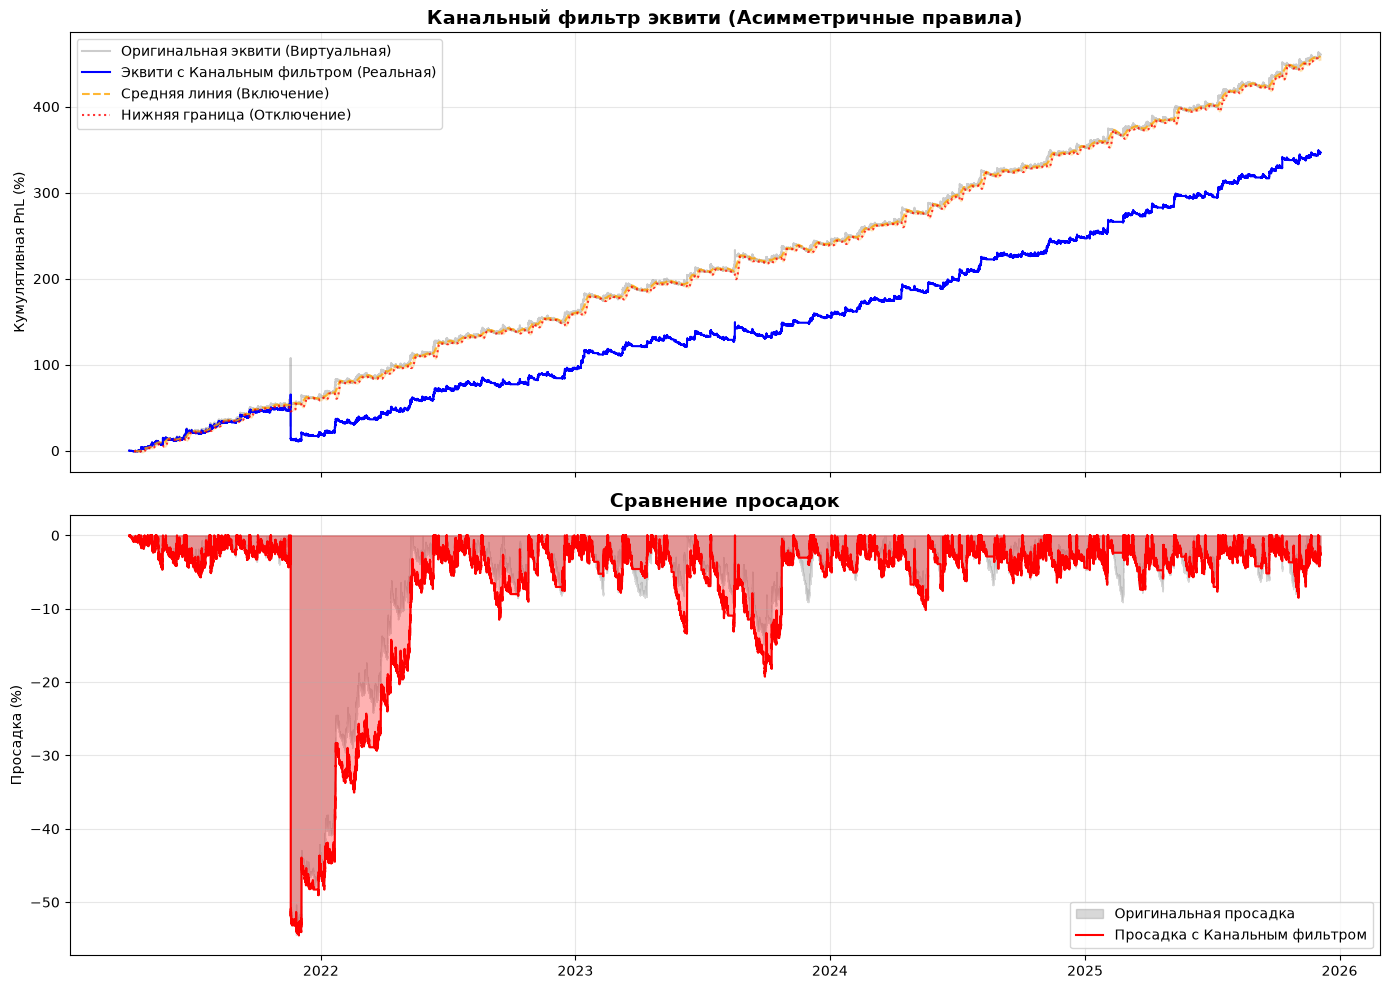

In [24]:
# 6. Визуализация (БЕЗОПАСНЫЙ ВАРИАНТ)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Верхний график
ax1.plot(portfolio_equity_curve.index, portfolio_equity_curve, label='Оригинальная эквити (Виртуальная)', color='gray', alpha=0.4)
ax1.plot(filtered_equity_bb.index, filtered_equity_bb, label='Эквити с Канальным фильтром (Реальная)', color='blue', linewidth=1.5)

# Рисуем линии канала
ax1.plot(equity_mean.index, equity_mean, color='orange', linestyle='--', alpha=0.8, label='Средняя линия (Включение)')
ax1.plot(lower_band.index, lower_band, color='red', linestyle=':', alpha=0.8, label='Нижняя граница (Отключение)')

# === ИСПРАВЛЕНИЕ: БЕЗОПАСНАЯ ЗАЛИВКА ===
# Собираем данные в таблицу и удаляем все строки, где есть NaN
valid_bands = pd.DataFrame({'mean': equity_mean, 'lower': lower_band}).dropna()
ax1.fill_between(valid_bands.index, valid_bands['lower'], valid_bands['mean'], color='orange', alpha=0.2)
# ======================================

ax1.set_title('Канальный фильтр эквити (Асимметричные правила)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Кумулятивная PnL (%)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Нижний график
ax2.fill_between(drawdown_curve.index, drawdown_curve, 0, color='gray', alpha=0.3, label='Оригинальная просадка')
ax2.plot(drawdown_bb.index, drawdown_bb, color='red', linewidth=1.5, label='Просадка с Канальным фильтром')
ax2.fill_between(drawdown_bb.index, drawdown_bb, 0, color='red', alpha=0.3)

ax2.set_title('Сравнение просадок', fontsize=14, fontweight='bold')
ax2.set_ylabel('Просадка (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()